# Análise exploratória dos comentários

Conhecer a base de avaliações da Olist antes de montar a base de conhecimento. Cada seção responde a uma pergunta, registra o que se esperava encontrar e alimenta uma decisão de preparação dos dados.

| # | Pergunta | Decisão que alimenta |
|---|---|---|
| 1 | Quem deixa comentário? | como as respostas descrevem percentuais (comentários ou clientes) |
| 2 | Como as notas se distribuem? | descrição da base |
| 3 | Qual o tamanho dos comentários? | uso do comentário inteiro como unidade de busca |
| 4 | Como o volume varia no tempo? | períodos com dados suficientes para responder |
| 5 | Há avaliações duplicadas? | cada comentário entra uma única vez na base |
| 6 | Os comentários negativos são mais específicos que os positivos? | composição da amostra para a lista de temas |

📌 Fonte: Brazilian E-Commerce Public Dataset by Olist (Kaggle), arquivos em `data/raw`.

## Carregamento

A tabela de avaliações traz a nota, o título e o texto do comentário, e as datas de criação e de resposta da avaliação. As demais tabelas da base entram na etapa de enriquecimento.

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS = RAIZ / "data" / "raw"

avaliacoes = pd.read_csv(
    DADOS / "olist_order_reviews_dataset.csv",
    parse_dates=["review_creation_date", "review_answer_timestamp"],
)

print(f"{len(avaliacoes):,} avaliações, {avaliacoes.shape[1]} colunas".replace(",", "."))
display(avaliacoes.head())
display(avaliacoes.isna().sum().to_frame("ausentes"))

99.224 avaliações. 7 colunas


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


,ausentes
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


**Leitura.** A base tem 99.224 avaliações. A nota e as datas estão completas. O texto do comentário falta em 58.247 avaliações (58,7%): apenas 40.977 têm comentário escrito. O título é ainda mais raro, presente em 11.568 avaliações (11,7%).

⚠️ Os nomes de lojas citados nos comentários foram substituídos pela Olist por nomes de casas de Game of Thrones (por exemplo, "lojas lannister"), como parte da anonimização descrita na página do conjunto de dados. Esses nomes não correspondem a lojas reais.

## 1. Quem deixa comentário?

**Hipótese.** Clientes insatisfeitos têm mais motivo para escrever, então comentam mais que os satisfeitos.

**Previsão.** A proporção de avaliações com comentário é maior nas notas 1 e 2 do que na nota 5.

**Por que importa.** Se a previsão se confirmar, os comentários dão mais peso à insatisfação do que ela tem no conjunto dos clientes. Um percentual calculado sobre os comentários, então, não descreve os clientes como um todo, e as respostas do sistema precisam deixar isso claro.

,avaliacoes,com_comentario,pct_com_comentario,pct_no_total,pct_nos_comentarios
review_score,,,,,
1,11424,8744,76.5,11.5,21.4
2,3151,2145,68.1,3.2,5.2
3,8179,3556,43.5,8.2,8.7
4,19142,5970,31.2,19.3,14.6
5,57328,20535,35.8,57.8,50.1


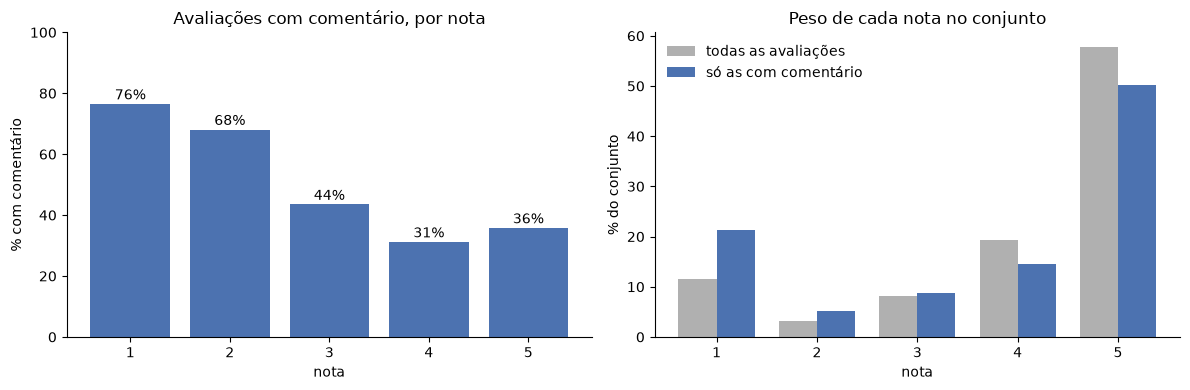

In [10]:
avaliacoes["tem_comentario"] = avaliacoes["review_comment_message"].fillna("").str.strip().ne("")

por_nota = avaliacoes.groupby("review_score").agg(
    avaliacoes=("review_id", "size"),
    com_comentario=("tem_comentario", "sum"),
)
por_nota["pct_com_comentario"] = (por_nota["com_comentario"] / por_nota["avaliacoes"] * 100).round(1)
por_nota["pct_no_total"] = (por_nota["avaliacoes"] / por_nota["avaliacoes"].sum() * 100).round(1)
por_nota["pct_nos_comentarios"] = (por_nota["com_comentario"] / por_nota["com_comentario"].sum() * 100).round(1)
display(por_nota)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(por_nota.index, por_nota["pct_com_comentario"], color="#4C72B0")
for nota, pct in por_nota["pct_com_comentario"].items():
    ax1.text(nota, pct + 1.5, f"{pct:.0f}%", ha="center")
ax1.set(title="Avaliações com comentário, por nota", xlabel="nota", ylabel="% com comentário", ylim=(0, 100))

largura = 0.38
ax2.bar(por_nota.index - largura / 2, por_nota["pct_no_total"], largura, label="todas as avaliações", color="#B0B0B0")
ax2.bar(por_nota.index + largura / 2, por_nota["pct_nos_comentarios"], largura, label="só as com comentário", color="#4C72B0")
ax2.set(title="Peso de cada nota no conjunto", xlabel="nota", ylabel="% do conjunto")
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.set_xticks(por_nota.index)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Leitura.** A previsão se confirmou. Deixam comentário 76,5% das avaliações de nota 1 e 68,1% das de nota 2, contra 35,8% das de nota 5. Com isso, a nota 1 representa 11,5% das avaliações, mas 21,4% dos comentários: quase o dobro do peso. Somadas, as notas 1 e 2 passam de 14,7% das avaliações para 26,6% dos comentários.

A nota 4 é a que menos comenta (31,2%), abaixo até da nota 5. Uma explicação plausível é que quem dá nota 4 ficou satisfeito sem entusiasmo, e não tem nem elogio nem reclamação a fazer.

**Consequência.** Os comentários exageram o peso da insatisfação. Um percentual calculado sobre eles descreve os comentários, não os clientes, e as respostas do sistema devem dizer isso explicitamente ("X% dos comentários", nunca "X% dos clientes").

## 2. Como as notas se distribuem?

Respondida pela tabela da seção anterior (coluna `pct_no_total`). A nota 5 concentra 57,8% das avaliações, seguida da nota 4 (19,3%) e da nota 1 (11,5%). As notas 2 e 3 somam 11,4%. É o formato esperado em avaliações de e-commerce: muita satisfação, um bloco menor de insatisfação forte e pouco no meio.

## 3. Qual o tamanho dos comentários?

**Hipótese.** Comentários de avaliação são curtos, de uma ou duas frases.

**Previsão.** Nove em cada dez comentários têm até cerca de 30 palavras, e nenhum passa muito de 40. Os comentários de nota baixa são mais longos que os de nota alta.

**Por que importa.** Se os comentários forem curtos, cada um pode entrar inteiro na base de busca, sem divisão em pedaços.

,caracteres,palavras
count,40950.0,40950.0
mean,68.3,11.7
std,53.7,9.6
min,1.0,1.0
25%,28.0,4.0
50%,53.0,9.0
75%,94.0,16.0
90%,160.0,28.0
99%,200.0,37.0
max,208.0,45.0


,count,mean,std,min,50%,90%,max
review_score,,,,,,,
1,8744.0,17.5,10.6,1.0,15.0,33.0,45.0
2,2145.0,17.1,10.5,1.0,15.0,33.0,43.0
3,3556.0,14.7,10.4,1.0,12.0,32.0,45.0
4,5970.0,10.6,9.2,1.0,8.0,25.0,41.0
5,20535.0,8.4,7.0,1.0,7.0,18.0,45.0


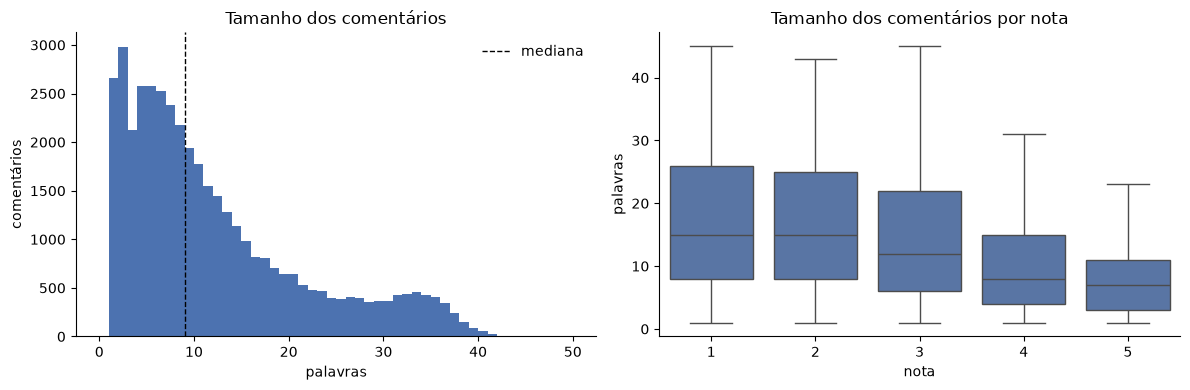

In [11]:
comentarios = avaliacoes[avaliacoes["tem_comentario"]].copy()
comentarios["texto"] = comentarios["review_comment_message"].str.replace(r"\s+", " ", regex=True).str.strip()
comentarios["caracteres"] = comentarios["texto"].str.len()
comentarios["palavras"] = comentarios["texto"].str.split().str.len()

display(comentarios[["caracteres", "palavras"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1))
display(comentarios.groupby("review_score")["palavras"].describe(percentiles=[0.5, 0.9]).round(1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(comentarios["palavras"], bins=range(0, 51), color="#4C72B0")
ax1.axvline(comentarios["palavras"].median(), color="black", ls="--", lw=1, label="mediana")
ax1.set(title="Tamanho dos comentários", xlabel="palavras", ylabel="comentários")
ax1.legend(frameon=False)

sns.boxplot(data=comentarios, x="review_score", y="palavras", color="#4C72B0", showfliers=False, ax=ax2)
ax2.set(title="Tamanho dos comentários por nota", xlabel="nota", ylabel="palavras")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Leitura.** A previsão se confirmou. A mediana é de 9 palavras (53 caracteres), 90% dos comentários têm até 28 palavras e o maior tem 45 palavras (208 caracteres). Os comentários de nota 1 e 2 têm mediana de 15 palavras, o dobro da nota 5 (7 palavras).

Há um acúmulo de comentários entre 30 e 37 palavras, e 99% têm até 200 caracteres, com máximo de 208. O padrão sugere um limite de tamanho no formulário de avaliação: quem queria escrever mais foi interrompido. A conferir na seção de ruído, procurando comentários que terminam cortados.

**Consequência.** Cada comentário entra inteiro na base de busca, sem divisão em pedaços. O tamanho maior nas notas baixas é coerente com a hipótese da seção 6, mas não a testa: um elogio pode ser longo e genérico.

## 6. Os comentários negativos são mais específicos que os positivos?

Esta seção vem antes das seções 4 e 5 porque decide a composição da amostra usada para montar a lista de temas.

**Hipótese.** O cliente insatisfeito descreve o motivo com riqueza de detalhe, enquanto o satisfeito tende a frases genéricas ("adoro a empresa", "sempre fui bem tratado", "nota 10").

**Previsão.** Em relação às notas 1 e 2, os comentários de nota 5 se repetem mais (frases feitas), citam menos referências concretas (prazo, número, parte do produto, etapa do processo) e, numa leitura humana às cegas, são classificados como genéricos com mais frequência.

**Por que importa.** Se os elogios forem majoritariamente genéricos, a amostra para a lista de temas deve dar mais peso aos comentários negativos, mantendo positivos suficientes para responder à pergunta sobre o que os clientes elogiam. Se a especificidade for parecida, a amostra é equilibrada.

Três medidas, da mais automática para a mais confiável:

1. **Repetição:** proporção de comentários idênticos a outros, depois de normalizar caixa, acentos e pontuação.
2. **Referência concreta:** proporção de comentários que citam algo verificável. É uma medida aproximada, baseada em listas de palavras.
3. **Leitura humana:** prevista como confirmação, foi dispensada (ver conclusão da seção).

In [12]:
import re
import unicodedata


def normalizar(texto):
    texto = unicodedata.normalize("NFKD", texto.lower())
    texto = "".join(ch for ch in texto if not unicodedata.combining(ch))
    texto = re.sub(r"[^a-z0-9 ]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


comentarios["normalizado"] = comentarios["texto"].map(normalizar)
vezes = comentarios["normalizado"].map(comentarios["normalizado"].value_counts())
comentarios["repetido"] = (vezes >= 2) & comentarios["normalizado"].ne("")

repeticao = comentarios.groupby("review_score")["repetido"].mean().mul(100).round(1)
display(repeticao.to_frame("% repetidos"))

mais_repetidos = (
    comentarios[comentarios["normalizado"].ne("")]
    .groupby("normalizado")
    .agg(vezes=("review_id", "size"), nota_media=("review_score", "mean"))
    .sort_values("vezes", ascending=False)
    .head(20)
    .round(1)
)
display(mais_repetidos)

,% repetidos
review_score,
1,9.7
2,8.7
3,13.6
4,24.5
5,27.6


,vezes,nota_media
normalizado,,
muito bom,598,4.7
otimo,471,4.8
bom,369,4.1
recomendo,316,4.7
excelente,214,4.9
otimo produto,168,4.8
ok,158,4.4
tudo ok,131,4.7
nao recebi o produto,111,1.2


,número,tempo e prazo,entrega e logística,troca e pagamento,característica do produto,alguma referência
review_score,,,,,,
1,22.1,22.0,31.3,17.3,13.7,66.4
2,20.9,22.6,30.6,11.5,18.7,65.6
3,13.2,22.2,28.3,7.7,16.7,57.7
4,5.7,27.5,27.9,2.8,9.9,50.2
5,4.5,30.2,28.7,0.9,4.2,47.9


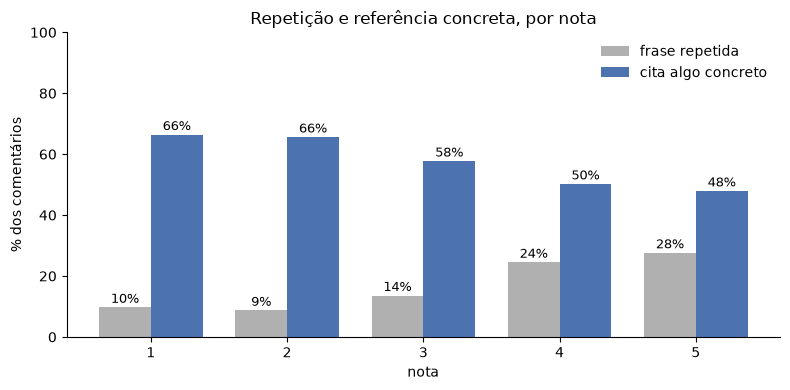

In [13]:
REFERENCIAS = {
    "número": r"\d",
    "tempo e prazo": r"\b(?:dias?|semanas?|mes|meses|prazo|atras\w*|demor\w*)\b",
    "entrega e logística": r"\b(?:entreg\w*|correios?|transportadora|rastre\w*|frete|endereco)\b",
    "troca e pagamento": r"\b(?:troca\w*|devol\w*|reembols\w*|estorn\w*|cancel\w*|nota fiscal|boleto|cartao|pagamento)\b",
    "característica do produto": r"\b(?:cor|tamanho|tecido|material|medidas?|defeito\w*|quebrad\w*|danificad\w*|rasgad\w*|riscad\w*|embalagem|caixa|pecas?|funciona\w*|manual|modelo)\b",
}

for nome, padrao in REFERENCIAS.items():
    comentarios[nome] = comentarios["normalizado"].str.contains(padrao, regex=True)
comentarios["alguma referência"] = comentarios[list(REFERENCIAS)].any(axis=1)

concretude = comentarios.groupby("review_score")[list(REFERENCIAS) + ["alguma referência"]].mean().mul(100).round(1)
display(concretude)

fig, ax = plt.subplots(figsize=(8, 4))
largura = 0.38
notas = concretude.index
ax.bar(notas - largura / 2, repeticao, largura, label="frase repetida", color="#B0B0B0")
ax.bar(notas + largura / 2, concretude["alguma referência"], largura, label="cita algo concreto", color="#4C72B0")
for nota in notas:
    ax.text(nota - largura / 2, repeticao[nota] + 1.5, f"{repeticao[nota]:.0f}%", ha="center", fontsize=9)
    ax.text(nota + largura / 2, concretude.loc[nota, "alguma referência"] + 1.5, f"{concretude.loc[nota, 'alguma referência']:.0f}%", ha="center", fontsize=9)
ax.set(title="Repetição e referência concreta, por nota", xlabel="nota", ylabel="% dos comentários", ylim=(0, 100))
ax.set_xticks(notas)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Leitura das medidas automáticas.** A repetição confirma a hipótese: 27,6% dos comentários de nota 5 são idênticos a outros, contra 9,7% na nota 1. As frases mais repetidas são elogios genéricos ("muito bom", 598 vezes; "ótimo", 471; "bom", "recomendo", "excelente"). As únicas frases negativas entre as 20 mais repetidas são "não recebi o produto" (111) e "ainda não recebi o produto" (63): nesse caso a repetição não indica frase feita, e sim uma queixa específica comum a muitos clientes.

A referência concreta também vai na direção da hipótese, com diferença menor que a esperada: 66,4% na nota 1 contra 47,9% na nota 5. A abertura por tipo explica a diferença. Os comentários de nota 5 citam prazo (30,2%) e entrega (28,7%) tanto quanto os de nota 1 (22,0% e 31,3%), porque o elogio mais comum é sobre entrega rápida. Já número (22,1% contra 4,5%), troca e pagamento (17,3% contra 0,9%) e característica do produto (13,7% contra 4,2%) aparecem quase só nas notas baixas.

O elogio, portanto, tem conteúdo, mas concentrado em poucos assuntos, sobretudo o prazo de entrega. A reclamação cobre um leque maior: produto errado ou incompleto, troca, pagamento, datas. A conclusão da seção depende da leitura humana, a seguir.

⚠️ **Limitações das medidas automáticas.**

- **Repetição** só reconhece cópias exatas depois da padronização (minúsculas, sem acento, sem pontuação). Variações da mesma ideia ("muito bom", "produto muito bom", "muito boa") contam como textos diferentes, o que subestima a proporção de frases feitas. Além disso, a repetição de uma queixa comum ("não recebi o produto") não indica comentário genérico.
- **Referência concreta** depende de uma lista de palavras. Ela conta como concreto todo elogio que cita prazo ou entrega ("entrega perfeita e bem antes do prazo"), e deixa de fora comentários específicos que citam o produto por palavras ausentes da lista ("chegou sem as baterias", "foram recebidas três capas de travesseiro das quatro compradas").

Os dois desvios reduzem a diferença medida entre as notas baixas e a nota 5. A diferença real tende a ser maior que a observada.

**Conclusão.** A hipótese se sustenta. Os comentários de nota 5 repetem frases feitas quase três vezes mais que os de nota 1, e quando têm conteúdo ele se concentra no prazo de entrega. Os de notas baixas citam números, troca, pagamento e características do produto com frequência muito maior. A leitura humana prevista foi dispensada: as duas medidas apontam na mesma direção, e os desvios conhecidos de ambas reduzem a diferença observada, em vez de ampliá-la.

**Decisões para a montagem da lista de temas** (registradas no diário de decisões):

1. Cada amostra de 1.000 comentários tem 60% de notas 1 e 2, 15% de nota 3 e 25% de notas 4 e 5. Os comentários negativos trazem a maior variedade de assuntos; a nota 3 concentra comentários com elogio e crítica juntos; os positivos têm poucos temas e se esgotam com uma parcela menor.
2. Comentários idênticos depois da padronização entram uma única vez na amostra. A frequência de cada um continua registrada para as contagens do sistema.
3. A lista de temas inclui a etiqueta "elogio geral, sem assunto", para que comentários como "muito bom" e "recomendo" sejam contados sem serem forçados num tema que não citam.

## 4. Como o volume varia no tempo?

**Hipótese.** O volume acompanha o crescimento da operação, e a insatisfação sobe em períodos de pressão sobre a logística.

**Previsão.** 2016 tem pouquíssimos comentários, o volume cresce ao longo de 2017 e 2018, e a proporção de comentários de nota 1 e 2 sobe depois da Black Friday de 2017 (24 de novembro) e da greve dos caminhoneiros (21 a 31 de maio de 2018), que paralisou o transporte de cargas no país.

📌 A data usada é a de envio da pesquisa de satisfação, que ocorre na entrega do pedido ou no vencimento do prazo previsto. O efeito de um evento logístico, portanto, deve aparecer com atraso: em dezembro de 2017 e em junho de 2018.

**Por que importa.** Meses com poucos comentários não sustentam conclusões, e o sistema deve recusar perguntas restritas a eles. A variação da insatisfação no tempo é o que a ferramenta de série temporal vai mostrar.

,avaliacoes,com_comentario,pct_negativos
mes,,,
2016-10,179,124,21.0
2016-11,101,79,44.3
2016-12,45,35,77.1
2017-01,239,120,13.3
2017-02,1413,592,18.4
2017-03,2481,1097,26.1
2017-04,2055,894,26.6
2017-05,3710,1536,23.0
2017-06,3440,1428,23.7


meses com menos de 100 comentários: 2 -> 2016-11, 2016-12


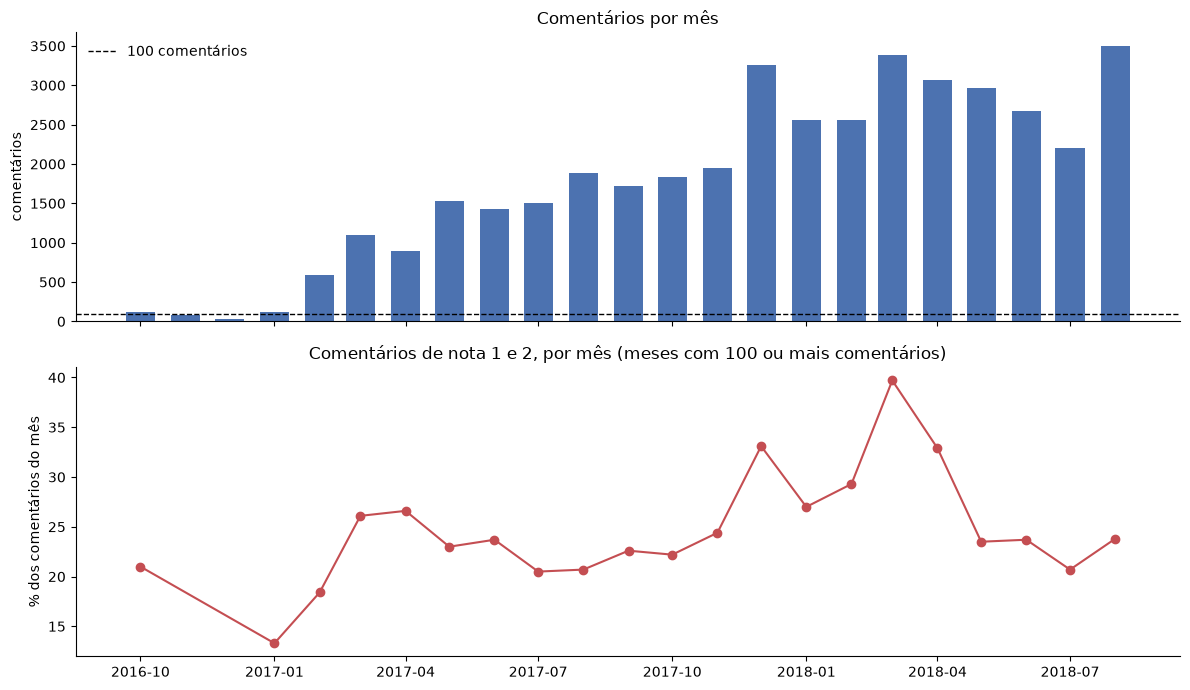

In [14]:
MINIMO_COMENTARIOS = 100

avaliacoes["mes"] = avaliacoes["review_creation_date"].dt.to_period("M")
comentarios["mes"] = comentarios["review_creation_date"].dt.to_period("M")

mensal = avaliacoes.groupby("mes").agg(
    avaliacoes=("review_id", "size"),
    com_comentario=("tem_comentario", "sum"),
)
mensal["pct_negativos"] = (
    comentarios.assign(negativo=comentarios["review_score"] <= 2).groupby("mes")["negativo"].mean().mul(100).round(1)
)
display(mensal)

poucos = mensal[mensal["com_comentario"] < MINIMO_COMENTARIOS]
print(f"meses com menos de {MINIMO_COMENTARIOS} comentários: {len(poucos)} -> {', '.join(str(m) for m in poucos.index)}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
x = mensal.index.to_timestamp()

ax1.bar(x, mensal["com_comentario"], width=20, color="#4C72B0")
ax1.axhline(MINIMO_COMENTARIOS, color="black", ls="--", lw=1, label=f"{MINIMO_COMENTARIOS} comentários")
ax1.set(title="Comentários por mês", ylabel="comentários")
ax1.legend(frameon=False)

confiavel = mensal["com_comentario"] >= MINIMO_COMENTARIOS
ax2.plot(x[confiavel], mensal.loc[confiavel, "pct_negativos"], marker="o", color="#C44E52")
ax2.set(title=f"Comentários de nota 1 e 2, por mês (meses com {MINIMO_COMENTARIOS} ou mais comentários)", ylabel="% dos comentários do mês")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Leitura.** O volume confirma a previsão. Novembro e dezembro de 2016 ficam abaixo de 100 comentários, e outubro de 2016 e janeiro de 2017 mal passam disso (124 e 120). O volume supera mil comentários por mês a partir de março de 2017 e chega a 3.498 em agosto de 2018.

A proporção de comentários de nota 1 e 2 fica entre 20% e 27% na maior parte de 2017 e sobe para 33,1% em dezembro de 2017, junto com um salto de volume (de 1.951 para 3.254 comentários). O aumento é compatível com a hipótese, mas não a isola: os pedidos da Black Friday e os de Natal recebem a pesquisa no mesmo mês, e a data da pesquisa não permite separar os dois. A leitura correta, por ora, é a de um efeito do pico de demanda de fim de ano. A separação é possível com a data de compra, disponível na tabela de pedidos, comparando compras feitas na semana da Black Friday com compras feitas no início de dezembro. A greve dos caminhoneiros, ao contrário do previsto, não aparece: junho de 2018 fica em 23,7%, no patamar habitual. O pico da série, não previsto, está entre fevereiro e abril de 2018, com 39,7% em março. A causa não é identificável nesta tabela. Se for logística, deve aparecer no atraso real das entregas por mês, que será calculado na etapa de enriquecimento.

**Consequência.** Os meses até janeiro de 2017 têm poucos comentários e não sustentam conclusões isoladas. O limite mínimo de evidência usado pelo sistema será definido junto com as ferramentas, com 100 comentários por mês como referência inicial.

## 5. Há avaliações duplicadas?

**Hipótese.** A Olist envia uma pesquisa de satisfação por compra, e uma compra pode gerar mais de um pedido. Assim, a mesma avaliação pode aparecer ligada a pedidos diferentes, e um pedido pode ter recebido mais de uma avaliação.

**Previsão.** Os dois casos existem, mas são raros (menos de 2% das linhas).

**Por que importa.** Cada comentário deve entrar uma única vez na base. Uma avaliação repetida inflaria as contagens e apareceria duas vezes como evidência.

In [15]:
review_repetido = avaliacoes["review_id"].duplicated(keep=False)
pedido_repetido = avaliacoes["order_id"].duplicated(keep=False)

resumo = pd.Series({
    "linhas": len(avaliacoes),
    "review_id distintos": avaliacoes["review_id"].nunique(),
    "linhas com review_id repetido": review_repetido.sum(),
    "order_id distintos": avaliacoes["order_id"].nunique(),
    "linhas com order_id repetido": pedido_repetido.sum(),
    "comentários com review_id repetido": comentarios["review_id"].duplicated(keep=False).sum(),
})
display(resumo.to_frame("quantidade"))

colunas = ["review_id", "order_id", "review_score", "review_comment_message", "review_creation_date"]
print("Exemplos: mesma avaliação ligada a pedidos diferentes")
display(avaliacoes.loc[review_repetido & avaliacoes["tem_comentario"], colunas].sort_values("review_id").head(6))
print("Exemplos: mesmo pedido com mais de uma avaliação")
display(avaliacoes.loc[pedido_repetido, colunas].sort_values("order_id").head(6))

,quantidade
linhas,99224
review_id distintos,98410
linhas com review_id repetido,1603
order_id distintos,98673
linhas com order_id repetido,1098
comentários com review_id repetido,608


Exemplos: mesma avaliação ligada a pedidos diferentes


,review_id,order_id,review_score,review_comment_message,review_creation_date
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,Produto entregue dentro de embalagem do fornec...,2018-03-07
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,Produto entregue dentro de embalagem do fornec...,2018-03-07
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,O pedido consta de 2 produtos e até agora rece...,2017-09-09
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,O pedido consta de 2 produtos e até agora rece...,2017-09-09


Exemplos: mesmo pedido com mais de uma avaliação


,review_id,order_id,review_score,review_comment_message,review_creation_date
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,Estou acostumada a comprar produtos pelo barat...,2017-08-25
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,2017-08-29
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,2018-02-22
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,2018-03-04
854,830636803620cdf8b6ffaf1b2f6e92b2,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,2017-12-30
83224,d8e8c42271c8fb67b9dad95d98c8ff80,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,2017-12-30


**Leitura.** Os dois casos existem e são raros, como previsto. Há 98.410 avaliações distintas em 99.224 linhas: 1.603 linhas (1,6%) compartilham o código de avaliação com outra. Os exemplos mostram a mesma avaliação, com texto e data idênticos, ligada a pedidos diferentes, o que indica uma pesquisa respondida uma vez e replicada para os pedidos de uma mesma compra. Entre as linhas com comentário, 608 estão nessa situação. No sentido inverso, 1.098 linhas (1,1%) pertencem a pedidos com mais de uma avaliação, em geral sem comentário e com datas diferentes.

**Consequência.** A base de conhecimento terá um documento por código de avaliação, e não por linha da tabela, para que nenhum comentário seja contado ou exibido duas vezes. Como uma avaliação pode estar ligada a mais de um pedido, a forma de associar categoria e prazo de entrega a ela será decidida na etapa de enriquecimento.